In [3]:
import pandas as pd
import matplotlib.pyplot as plt

In [5]:
df = pd.read_csv("train.csv")

print("Dataset shape:", df.shape)

df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'train.csv'

In [7]:
import os

print("Current folder:", os.getcwd())
print("Files in this folder:", os.listdir())

Current folder: C:\Users\mukesh
Files in this folder: ['.anaconda', '.anaconda-desktop', '.antigravity', '.antigravity-ide', '.arduinoIDE', '.cache', '.claude', '.conda', '.condarc', '.copilot', '.eclipse', '.gemini', '.gitconfig', '.ipynb_checkpoints', '.ipython', '.jupyter', '.m2', '.mamba', '.node_repl_history', '.ollama', '.p2', '.th-client', '.VirtualBox', '.vscode', '.vscode-shared', 'agritech-ai-platform', 'AppData', 'Application Data', 'Contacts', 'Cookies', 'Desktop', 'Documents', 'Downloads', 'eclipse', 'eclipse-workspace', 'Favorites', 'Links', 'Local Settings', 'Music', 'music.csv', 'Music_Genre_Recommendation.ipynb', 'music_recommender.joblib', 'My Documents', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{460cf797-5431-11f0-b65f-50bbb55fbb01}.TM.blf', 'NTUSER.DAT{460cf797-5431-11f0-b65f-50bbb55fbb01}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{460cf797-5431-11f0-b65f-50bbb55fbb01}.TMContainer00000000000000000002.regtrans-ms', 'ntu

In [9]:
import os

for folder in ["Downloads", "Desktop", "Documents"]:
    path = os.path.join(os.path.expanduser("~"), folder)

    for root, dirs, files in os.walk(path):
        if "train.csv" in files:
            print("Found:", os.path.join(root, "train.csv"))

Found: C:\Users\mukesh\Downloads\train.csv


In [10]:

import pandas as pd

df = pd.read_csv(r"C:\Users\mukesh\Downloads\train.csv")

print("Dataset shape:", df.shape)

df.head()


Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [14]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [16]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [18]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [20]:
# Fill missing ages using the median age
df["Age"] = df["Age"].fillna(df["Age"].median())

# Fill missing embarkation ports using the most common port
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

# Remove Cabin because most of its values are missing
df = df.drop(columns=["Cabin"])

# Verify the cleaning
print("Missing values after cleaning:")
print(df.isnull().sum())

KeyError: "['Cabin'] not found in axis"

In [21]:
print(df.columns.tolist())

['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Embarked']


In [22]:

# Fill missing Age values
if "Age" in df.columns:
    df["Age"] = df["Age"].fillna(df["Age"].median())

# Fill missing Embarked values
if "Embarked" in df.columns:
    df["Embarked"] = df["Embarked"].fillna(
        df["Embarked"].mode()[0]
    )

# Remove Cabin only if it exists
if "Cabin" in df.columns:
    df = df.drop(columns=["Cabin"])

# Verify missing values
print("Missing values after cleaning:")
print(df.isnull().sum())

print("Dataset shape:", df.shape)


Missing values after cleaning:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64
Dataset shape: (891, 11)


In [24]:
df["Sex"] = df["Sex"].map({
    "male": 0,
    "female": 1
})

df[["Sex"]].head()

,Sex
0,NaN
1,NaN
2,NaN
3,NaN
4,NaN


In [25]:
df = pd.get_dummies(
    df,
    columns=["Embarked"],
    dtype=int
)

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,"Braund, Mr. Owen Harris",NaN,22.0,1,0,A/5 21171,7.2500,0,0,1
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",NaN,38.0,1,0,PC 17599,71.2833,1,0,0
2,3,1,3,"Heikkinen, Miss. Laina",NaN,26.0,0,0,STON/O2. 3101282,7.9250,0,0,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",NaN,35.0,1,0,113803,53.1000,0,0,1
4,5,0,3,"Allen, Mr. William Henry",NaN,35.0,0,0,373450,8.0500,0,0,1


In [27]:
print(df.columns.tolist())

print(df[["Sex", "Embarked_C", "Embarked_Q", "Embarked_S"]].head())

['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Embarked_C', 'Embarked_Q', 'Embarked_S']
   Sex  Embarked_C  Embarked_Q  Embarked_S
0  NaN           0           0           1
1  NaN           1           0           0
2  NaN           0           0           1
3  NaN           0           0           1
4  NaN           0           0           1


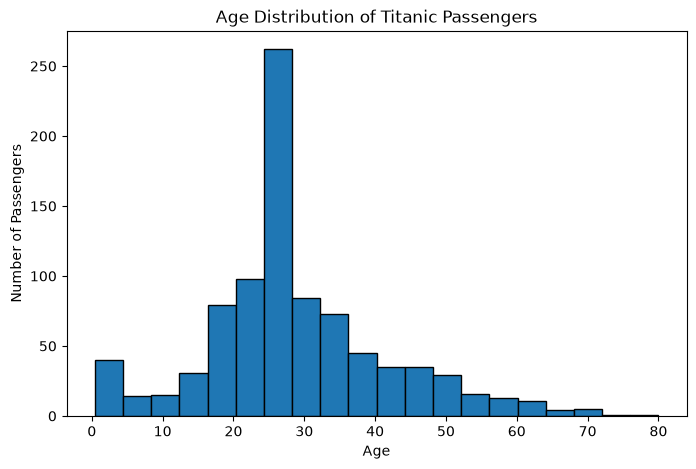

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(df["Age"], bins=20, edgecolor="black")

plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

In [29]:
df.to_csv("titanic_cleaned.csv", index=False)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!


In [30]:
import os
import pandas as pd

print("File exists:", os.path.exists("titanic_cleaned.csv"))

cleaned_df = pd.read_csv("titanic_cleaned.csv")

print("Dataset shape:", cleaned_df.shape)
print("Total missing values:", cleaned_df.isnull().sum().sum())

cleaned_df.head()

File exists: True
Dataset shape: (891, 13)
Total missing values: 891


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,"Braund, Mr. Owen Harris",NaN,22.0,1,0,A/5 21171,7.2500,0,0,1
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",NaN,38.0,1,0,PC 17599,71.2833,1,0,0
2,3,1,3,"Heikkinen, Miss. Laina",NaN,26.0,0,0,STON/O2. 3101282,7.9250,0,0,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",NaN,35.0,1,0,113803,53.1000,0,0,1
4,5,0,3,"Allen, Mr. William Henry",NaN,35.0,0,0,373450,8.0500,0,0,1


In [31]:

readme_content = """# Titanic Data Cleaning Project

## Objective
Clean the Titanic passenger dataset and prepare it for further analysis.

## Dataset
The dataset contains passenger information, including age, sex,
passenger class, fare, and survival status.

## Tasks Completed
1. Loaded the Titanic dataset using Pandas.
2. Inspected the dataset using info() and describe().
3. Filled missing Age values using the median.
4. Filled missing Embarked values using the mode.
5. Removed the Cabin column because it contained many missing values.
6. Encoded Sex into numerical values.
7. Encoded Embarked using one-hot encoding.
8. Visualized passenger age distribution using Matplotlib.
9. Exported the cleaned dataset as a CSV file.

## Files
- Titanic_Data_Cleaning.ipynb
- titanic_cleaned.csv

## Libraries Used
- Python
- Pandas
- Matplotlib
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme_content)

print("README.md created successfully!")


README.md created successfully!


In [32]:
import os

for filename in [
    "Titanic_Data_Cleaning.ipynb",
    "titanic_cleaned.csv",
    "README.md"
]:
    print(filename, "->", os.path.exists(filename))

Titanic_Data_Cleaning.ipynb -> False
titanic_cleaned.csv -> True
README.md -> True


In [33]:
import os

print("Current folder:", os.getcwd())

for file in [
    "Titanic_Data_Cleaning.ipynb",
    "titanic_cleaned.csv",
    "README.md"
]:
    print(file, "->", "Found" if os.path.exists(file) else "Missing")

Current folder: C:\Users\mukesh
Titanic_Data_Cleaning.ipynb -> Missing
titanic_cleaned.csv -> Found
README.md -> Found


In [34]:
print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Columns:", df.columns.tolist())

import os
print("CSV exported:", os.path.exists("titanic_cleaned.csv"))

Dataset shape: (891, 13)
Missing values: 891
Columns: ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Embarked_C', 'Embarked_Q', 'Embarked_S']
CSV exported: True


In [35]:
print(df.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex            891
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Embarked_C       0
Embarked_Q       0
Embarked_S       0
dtype: int64


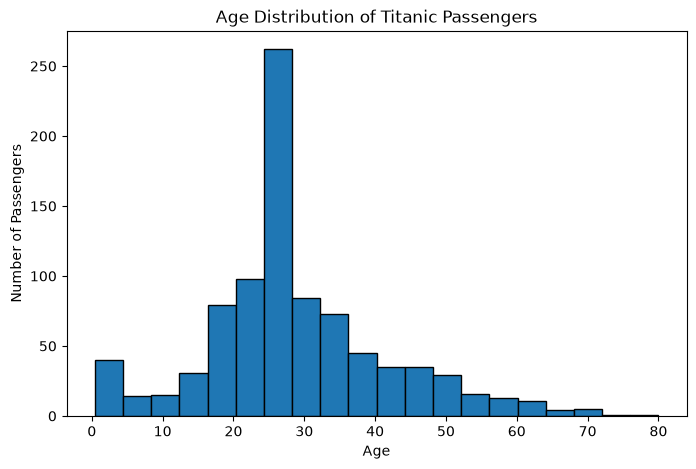

Dataset shape: (891, 13)
Missing values: 0
CSV exported: True

Missing values by column:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked_C     0
Embarked_Q     0
Embarked_S     0
dtype: int64


In [36]:

import pandas as pd
import matplotlib.pyplot as plt
import os

# 1. Reload the original dataset
df = pd.read_csv(r"C:\Users\mukesh\Downloads\train.csv")

# 2. Handle missing values
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

# 3. Remove Cabin
df = df.drop(columns=["Cabin"])

# 4. Encode Sex
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})

# 5. Encode Embarked
df = pd.get_dummies(df, columns=["Embarked"], dtype=int)

# 6. Visualize age distribution
plt.figure(figsize=(8, 5))
plt.hist(df["Age"], bins=20, edgecolor="black")
plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.show()

# 7. Export the cleaned dataset
df.to_csv("titanic_cleaned.csv", index=False)

# 8. Verify everything
print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("CSV exported:", os.path.exists("titanic_cleaned.csv"))
print("\nMissing values by column:")
print(df.isnull().sum())


In [37]:
# Titanic Data Cleaning and Exploratory Analysis

**Author:** Adharsh

## Project Overview

This project focuses on cleaning and preparing the Titanic passenger dataset using Python and Pandas. The goal is to handle missing values, encode categorical variables, visualize passenger age distribution, and export a clean dataset for further analysis.

## Objectives

- Load and inspect the Titanic dataset.
- Identify and handle missing values.
- Encode categorical columns into numerical representations.
- Visualize passenger age distribution using Matplotlib.
- Export the cleaned dataset as a CSV file.

## Dataset

The project uses the Titanic training dataset (`train.csv`), which contains passenger information such as:

- Passenger class
- Age and sex
- Number of siblings, spouses, parents, and children aboard
- Ticket fare
- Port of embarkation
- Survival status

The original dataset contains **891 rows and 12 columns**.

## Technologies Used

- **Python** — Programming language
- **Pandas** — Data manipulation and cleaning
- **Matplotlib** — Data visualization
- **Jupyter Notebook** — Interactive development environment

## Project Workflow

### 1. Data Loading and Inspection

Loaded the dataset using Pandas and examined its structure using `head()`, `info()`, and `describe()`.

### 2. Missing Value Handling

- Filled missing `Age` values using the median.
- Filled missing `Embarked` values using the most frequent value (mode).
- Removed the `Cabin` column because it contained a large number of missing values.

### 3. Categorical Encoding

- Converted `Sex` into numerical values (`male = 0`, `female = 1`).
- Applied one-hot encoding to `Embarked`, creating `Embarked_C`, `Embarked_Q`, and `Embarked_S`.

### 4. Data Visualization

Created a histogram using Matplotlib to visualize the age distribution of Titanic passengers.

### 5. Exporting the Cleaned Dataset

Saved the processed dataset as `titanic_cleaned.csv` for future analysis.

## Final Results

| Metric | Result |
|---|---:|
| Original rows | 891 |
| Original columns | 12 |
| Final rows | 891 |
| Final columns | 13 |
| Missing values after cleaning | 0 |

The final dataset contains 13 columns because the original `Cabin` column was removed and `Embarked` was replaced by three one-hot encoded columns.

## Project Files

- `Titanic_Data_Cleaning.ipynb` — Jupyter Notebook containing the code and analysis.
- `titanic_cleaned.csv` — Exported cleaned dataset.
- `README.md` — Project documentation.
- `train.csv` — Original dataset, if included locally.

## How to Run the Project

1. Install Python and Jupyter Notebook.
2. Install the required libraries:

   ```bash
   python -m pip install pandas matplotlib
   ```

3. Place `train.csv` in the notebook's working directory.
4. Open `Titanic_Data_Cleaning.ipynb` in Jupyter Notebook.
5. Run the notebook cells in order.
6. Find the exported `titanic_cleaned.csv` in the working directory.

## Learning Outcomes

Through this project, I practiced:

- Data inspection and preprocessing with Pandas.
- Handling missing numerical and categorical values.
- Encoding categorical features.
- Creating histograms with Matplotlib.
- Exporting cleaned data for further analysis.

## Future Improvements

- Perform more exploratory data analysis.
- Explore relationships between passenger attributes and survival.
- Build a machine learning model to predict passenger survival as a separate extension.

---

**Author:** Adharsh  
**Project:** Titanic Data Cleaning  
**Focus:** Data preprocessing and visualization


SyntaxError: invalid character '—' (U+2014) (141532714.py, line 32)

In [38]:

readme_content = r"""# Titanic Data Cleaning and Exploratory Analysis

**Author:** Adharsh

## Project Overview

This project focuses on cleaning and preparing the Titanic passenger dataset using Python, Pandas, and Matplotlib.

## Objectives

- Load and inspect the Titanic dataset.
- Identify and handle missing values.
- Encode categorical columns.
- Visualize passenger age distribution.
- Export the cleaned dataset as a CSV file.

## Technologies Used

- Python
- Pandas
- Matplotlib
- Jupyter Notebook

## Project Workflow

### 1. Data Loading and Inspection
Loaded the dataset using Pandas and inspected it with `head()`, `info()`, and `describe()`.

### 2. Missing Value Handling
- Filled missing `Age` values using the median.
- Filled missing `Embarked` values using the mode.
- Removed `Cabin` because it contained many missing values.

### 3. Categorical Encoding
- Encoded `Sex`: male = 0, female = 1.
- Applied one-hot encoding to `Embarked`, creating `Embarked_C`, `Embarked_Q`, and `Embarked_S`.

### 4. Data Visualization
Created a histogram using Matplotlib to visualize passenger age distribution.

### 5. Exporting the Dataset
Saved the cleaned dataset as `titanic_cleaned.csv`.

## Final Results

| Metric | Result |
|---|---:|
| Original rows | 891 |
| Original columns | 12 |
| Final rows | 891 |
| Final columns | 13 |
| Missing values after cleaning | 0 |

## Project Files

- `Titanic_Data_Cleaning.ipynb` - Notebook containing code and analysis.
- `titanic_cleaned.csv` - Cleaned dataset.
- `README.md` - Project documentation.

## How to Run

1. Install Python and Jupyter Notebook.
2. Install dependencies:

   `python -m pip install pandas matplotlib`

3. Place `train.csv` in the notebook's working directory.
4. Open `Titanic_Data_Cleaning.ipynb`.
5. Run the notebook cells in order.

## Learning Outcomes

- Data inspection and cleaning with Pandas.
- Handling missing values.
- Encoding categorical features.
- Creating visualizations with Matplotlib.
- Exporting cleaned datasets.

## Future Improvements

- Perform additional exploratory data analysis.
- Explore relationships between passenger attributes and survival.
- Build a survival prediction model as a separate extension.

---

**Author:** Adharsh
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme_content)

print("README.md created successfully!")


README.md created successfully!


In [39]:
import os

print("README exists:", os.path.exists("README.md"))
print("Saved location:", os.path.abspath("README.md"))

README exists: True
Saved location: C:\Users\mukesh\README.md


In [41]:
import os

files = [
    "Titanic_Data_Cleaning.ipynb",
    "titanic_cleaned.csv",
    "README.md"
]

for file in files:
    if os.path.exists(file):
        print(" Found:", os.path.abspath(file))
    else:
        print(" Missing:", file)

 Missing: Titanic_Data_Cleaning.ipynb
 Found: C:\Users\mukesh\titanic_cleaned.csv
 Found: C:\Users\mukesh\README.md
